In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report

import warnings
warnings.filterwarnings("ignore")

In [9]:
movies = pd.read_csv("tmdb_5000_movies.csv")
credits = pd.read_csv("tmdb_5000_credits.csv")

print("Movies dataset:", movies.shape)
print("Credits dataset:", credits.shape)

Movies dataset: (4803, 20)
Credits dataset: (4803, 4)


In [11]:
# View first 5 rows

movies.head()

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124


In [13]:
# Dataset information

movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   object 
 15  status               

In [15]:
# Statistical summary

movies.describe()

,budget,id,popularity,revenue,runtime,vote_average,vote_count
count,4.803000e+03,4803.000000,4803.000000,4.803000e+03,4801.000000,4803.000000,4803.000000
mean,2.904504e+07,57165.484281,21.492301,8.226064e+07,106.875859,6.092172,690.217989
std,4.072239e+07,88694.614033,31.816650,1.628571e+08,22.611935,1.194612,1234.585891
min,0.000000e+00,5.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,7.900000e+05,9014.500000,4.668070,0.000000e+00,94.000000,5.600000,54.000000
50%,1.500000e+07,14629.000000,12.921594,1.917000e+07,103.000000,6.200000,235.000000
75%,4.000000e+07,58610.500000,28.313505,9.291719e+07,118.000000,6.800000,737.000000
max,3.800000e+08,459488.000000,875.581305,2.787965e+09,338.000000,10.000000,13752.000000


In [17]:
credits.head()

,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,49026,The Dark Knight Rises,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,49529,John Carter,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."


In [19]:
credits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   movie_id  4803 non-null   int64 
 1   title     4803 non-null   object
 2   cast      4803 non-null   object
 3   crew      4803 non-null   object
dtypes: int64(1), object(3)
memory usage: 150.2+ KB


In [21]:
#missing values
movies.isnull().sum().sort_values(ascending=False)

homepage                3091
tagline                  844
overview                   3
runtime                    2
release_date               1
budget                     0
vote_average               0
title                      0
status                     0
spoken_languages           0
revenue                    0
production_countries       0
genres                     0
production_companies       0
popularity                 0
original_title             0
original_language          0
keywords                   0
id                         0
vote_count                 0
dtype: int64

In [23]:
#duplicates
print("Duplicate movie IDs:", movies["id"].duplicated().sum())
print("Duplicate credit IDs:", credits["movie_id"].duplicated().sum())

Duplicate movie IDs: 0
Duplicate credit IDs: 0


In [25]:
#Handle budget and revenue
movies["budget"] = movies["budget"].replace(0, np.nan)
movies["revenue"] = movies["revenue"].replace(0, np.nan)

In [27]:
movies[["budget", "revenue"]].isnull().sum()

budget     1037
revenue    1427
dtype: int64

In [31]:
#release year variables
movies["release_date"] = pd.to_datetime(
    movies["release_date"],
    errors="coerce"
)

movies["release_year"] = movies["release_date"].dt.year

In [33]:
# Check release year distribution

movies["release_year"].describe()

count    4802.000000
mean     2002.468763
std        12.414354
min      1916.000000
25%      1999.000000
50%      2005.000000
75%      2011.000000
max      2017.000000
Name: release_year, dtype: float64

In [35]:
# Check earliest and latest release years

print("Earliest release year:", movies["release_year"].min())
print("Latest release year:", movies["release_year"].max())

Earliest release year: 1916.0
Latest release year: 2017.0


In [37]:
movies["release_year"].isnull().sum()

1

In [39]:
#most recent movies
movies[
    ["title", "release_date", "release_year", "budget", "revenue"]
].sort_values(
    "release_date",
    ascending=False
).head(10)

,title,release_date,release_year,budget,revenue
4255,Growing Up Smith,2017-02-03,2017.0,NaN,NaN
3408,Two Lovers and a Bear,2016-10-02,2016.0,NaN,NaN
3302,Mr. Church,2016-09-16,2016.0,8000000.0,NaN
4720,The Birth of a Nation,2016-09-09,2016.0,8500000.0,15861566.0
3249,Kicks,2016-09-09,2016.0,NaN,NaN
4036,Antibirth,2016-09-02,2016.0,35000000.0,NaN
2273,Hands of Stone,2016-08-26,2016.0,20000000.0,NaN
357,Ben-Hur,2016-08-17,2016.0,100000000.0,94061311.0
3013,Pete's Dragon,2016-08-10,2016.0,65000000.0,143695338.0
72,Suicide Squad,2016-08-02,2016.0,175000000.0,745000000.0


In [41]:
#highest-grossing movies
movies[
    ["title", "budget", "revenue", "vote_average", "popularity"]
].sort_values(
    "revenue",
    ascending=False
).head(10)

,title,budget,revenue,vote_average,popularity
0,Avatar,237000000.0,2.787965e+09,7.2,150.437577
25,Titanic,200000000.0,1.845034e+09,7.5,100.025899
16,The Avengers,220000000.0,1.519558e+09,7.4,144.448633
28,Jurassic World,150000000.0,1.513529e+09,6.5,418.708552
44,Furious 7,190000000.0,1.506249e+09,7.3,102.322217
7,Avengers: Age of Ultron,280000000.0,1.405404e+09,7.3,134.279229
124,Frozen,150000000.0,1.274219e+09,7.3,165.125366
31,Iron Man 3,200000000.0,1.215440e+09,6.8,77.682080
546,Minions,74000000.0,1.156731e+09,6.4,875.581305
26,Captain America: Civil War,250000000.0,1.153304e+09,7.1,198.372395


In [43]:
#highest-rated movies
movies[
    ["title", "vote_average", "vote_count", "revenue"]
].sort_values(
    "vote_average",
    ascending=False
).head(10)

,title,vote_average,vote_count,revenue
3519,Stiff Upper Lips,10.0,1,NaN
4247,Me You and Five Bucks,10.0,2,NaN
4045,"Dancer, Texas Pop. 81",10.0,1,565592.0
4662,Little Big Top,10.0,1,NaN
3992,Sardaarji,9.5,2,NaN
2386,One Man's Hero,9.3,2,NaN
2970,There Goes My Baby,8.5,2,123509.0
1881,The Shawshank Redemption,8.5,8205,28341469.0
2796,The Prisoner of Zenda,8.4,11,NaN
3337,The Godfather,8.4,5893,245066411.0


In [45]:
#popularity
movies[
    ["title", "popularity", "vote_average", "vote_count", "revenue"]
].sort_values(
    "popularity",
    ascending=False
).head(10)

,title,popularity,vote_average,vote_count,revenue
546,Minions,875.581305,6.4,4571,1.156731e+09
95,Interstellar,724.247784,8.1,10867,6.751200e+08
788,Deadpool,514.569956,7.4,10995,7.831130e+08
94,Guardians of the Galaxy,481.098624,7.9,9742,7.733286e+08
127,Mad Max: Fury Road,434.278564,7.2,9427,3.788583e+08
28,Jurassic World,418.708552,6.5,8662,1.513529e+09
199,Pirates of the Caribbean: The Curse of the Bla...,271.972889,7.5,6985,6.550112e+08
82,Dawn of the Planet of the Apes,243.791743,7.3,4410,7.106446e+08
200,The Hunger Games: Mockingjay - Part 1,206.227151,6.6,5584,7.521002e+08
88,Big Hero 6,203.734590,7.8,6135,6.521054e+08


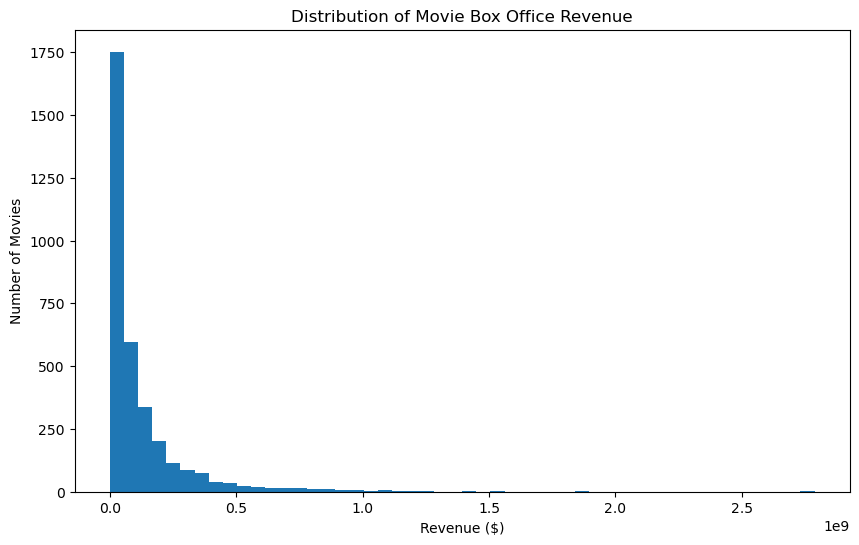

In [47]:
# Revenue distribution

plt.figure(figsize=(10, 6))

plt.hist(
    movies["revenue"].dropna(),
    bins=50
)

plt.title("Distribution of Movie Box Office Revenue")
plt.xlabel("Revenue ($)")
plt.ylabel("Number of Movies")

plt.show()

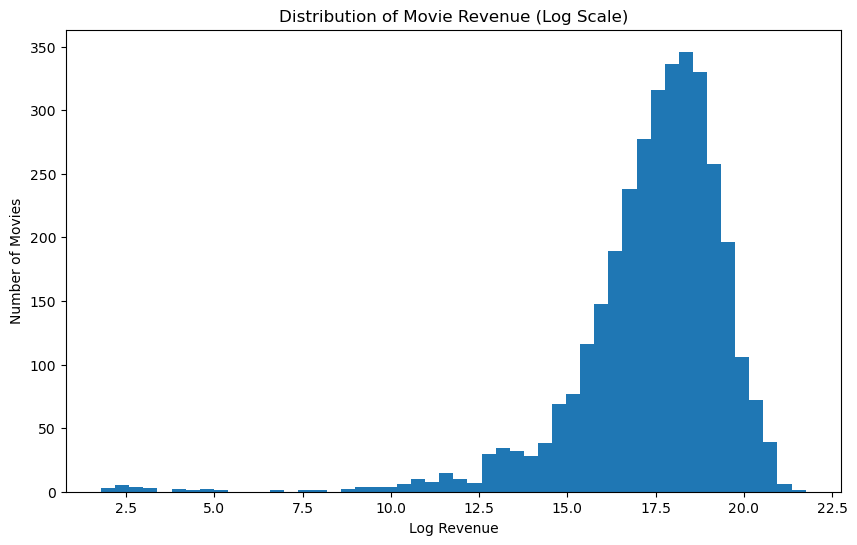

In [55]:
# Log-transformed revenue distribution

movies["log_revenue"] = np.log1p(movies["revenue"])

plt.figure(figsize=(10, 6))

plt.hist(
    movies["log_revenue"].dropna(),
    bins=50
)

plt.title("Distribution of Movie Revenue (Log Scale)")
plt.xlabel("Log Revenue")
plt.ylabel("Number of Movies")

plt.show()

In [57]:
movies["log_revenue"] = np.log1p(movies["revenue"])

In [65]:
# Revenue by release year

yearly_revenue = (
    movies.dropna(subset=["release_year", "revenue"])
    .groupby("release_year")["revenue"]
    .sum()
    .reset_index()
)

yearly_revenue.head()

,release_year,revenue
84,2012.0,2.414171e+10
85,2013.0,2.341149e+10
86,2014.0,2.412049e+10
87,2015.0,2.277502e+10
88,2016.0,1.446116e+10


In [68]:
yearly_revenue.tail()

,release_year,revenue
84,2012.0,2.414171e+10
85,2013.0,2.341149e+10
86,2014.0,2.412049e+10
87,2015.0,2.277502e+10
88,2016.0,1.446116e+10


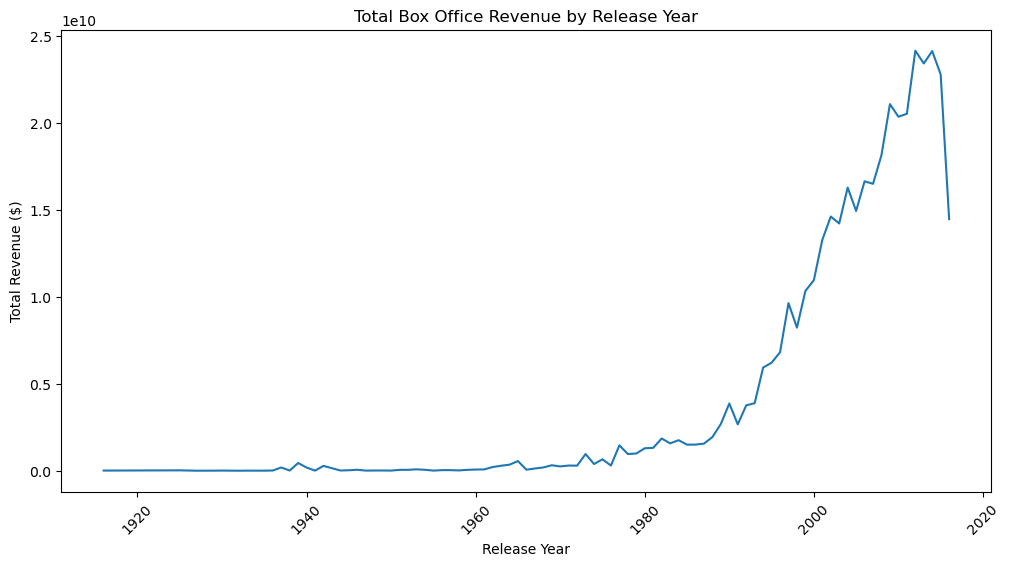

In [63]:
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_revenue["release_year"],
    yearly_revenue["revenue"]
)

plt.title("Total Box Office Revenue by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Total Revenue ($)")
plt.xticks(rotation=45)

plt.show()

In [74]:
# number of movies released per year
movies_per_year = (
    movies.dropna(subset=["release_year"])
    .groupby("release_year")
    .size()
    .reset_index(name="movie_count")
)

movies_per_year.head()

,release_year,movie_count
0,1916.0,1
1,1925.0,1
2,1927.0,1
3,1929.0,2
4,1930.0,1


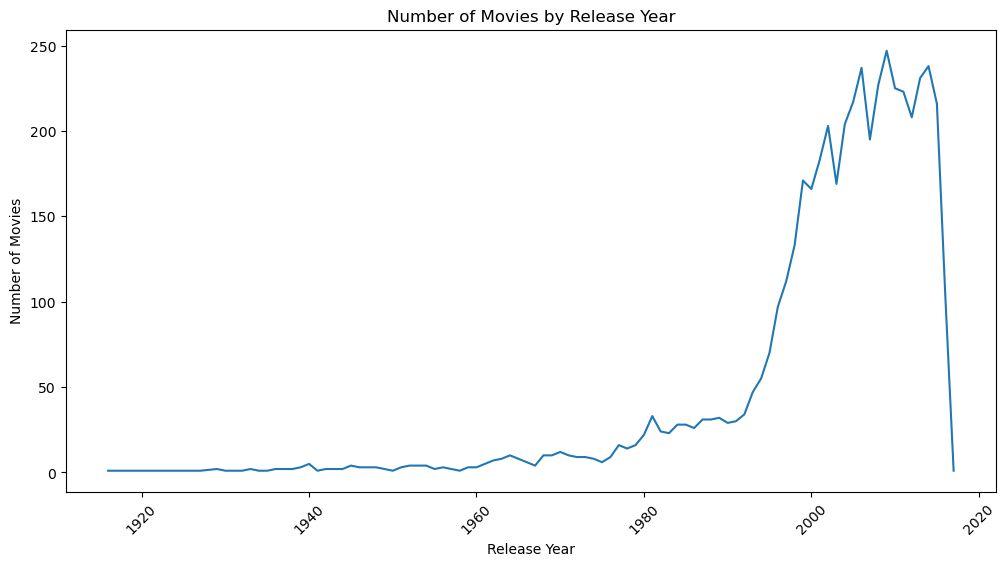

In [72]:
plt.figure(figsize=(12, 6))

plt.plot(
    movies_per_year["release_year"],
    movies_per_year["movie_count"]
)

plt.title("Number of Movies by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)

plt.show()

In [76]:
#calculate average revenue per movie
# Average box office revenue per movie by year

avg_revenue_year = (
    movies.dropna(subset=["release_year", "revenue"])
    .groupby("release_year")["revenue"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

avg_revenue_year.columns = [
    "release_year",
    "average_revenue",
    "median_revenue",
    "movie_count"
]

avg_revenue_year.tail(10)

,release_year,average_revenue,median_revenue,movie_count
79,2007.0,1.239972e+08,59192128.0,133
80,2008.0,1.155827e+08,50907234.0,157
81,2009.0,1.308860e+08,42333295.0,161
82,2010.0,1.189975e+08,49779728.0,171
83,2011.0,1.152636e+08,56512493.5,178
84,2012.0,1.609447e+08,64793040.0,150
85,2013.0,1.436288e+08,63464861.0,163
86,2014.0,1.686748e+08,80383290.0,143
87,2015.0,1.807542e+08,84769058.0,126
88,2016.0,1.980980e+08,108286421.0,73


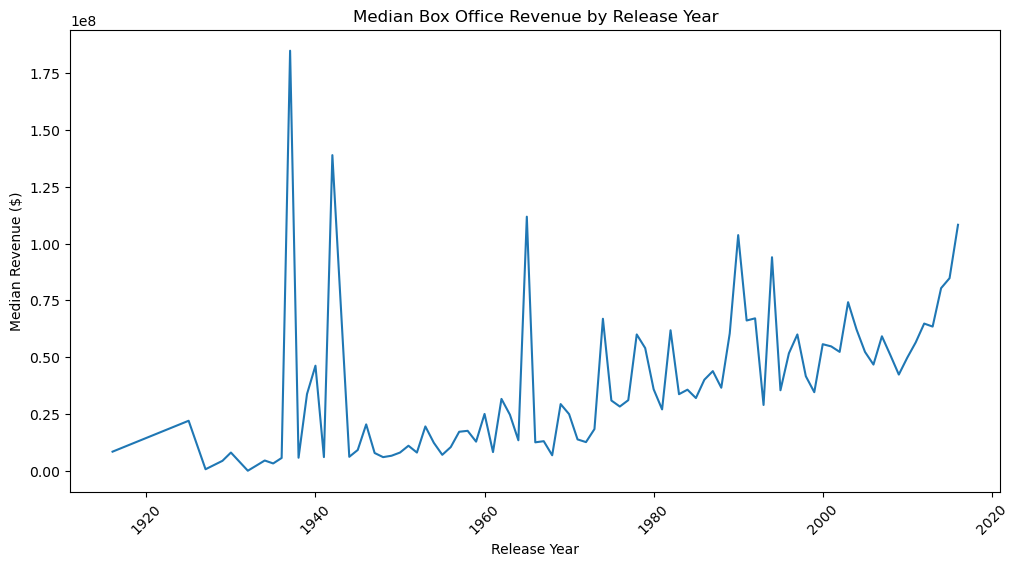

In [78]:
plt.figure(figsize=(12, 6))

plt.plot(
    avg_revenue_year["release_year"],
    avg_revenue_year["median_revenue"]
)

plt.title("Median Box Office Revenue by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Median Revenue ($)")
plt.xticks(rotation=45)

plt.show()

In [82]:
# FORECASTING DATASET

forecast_data = avg_revenue_year[
    (avg_revenue_year["release_year"] >= 1990) &
    (avg_revenue_year["movie_count"] >= 20)
].copy()

forecast_data.head()

,release_year,average_revenue,median_revenue,movie_count
62,1990.0,1.679901e+08,103738726.0,23
63,1991.0,1.210958e+08,66145834.0,22
64,1992.0,1.252302e+08,67094276.0,30
65,1993.0,1.078320e+08,28950000.0,36
66,1994.0,1.378780e+08,94000000.0,43


In [84]:
forecast_data.tail()

,release_year,average_revenue,median_revenue,movie_count
84,2012.0,1.609447e+08,64793040.0,150
85,2013.0,1.436288e+08,63464861.0,163
86,2014.0,1.686748e+08,80383290.0,143
87,2015.0,1.807542e+08,84769058.0,126
88,2016.0,1.980980e+08,108286421.0,73


In [86]:
print("Number of years:", len(forecast_data))
print(
    "Forecast period:",
    int(forecast_data["release_year"].min()),
    "to",
    int(forecast_data["release_year"].max())
)

Number of years: 27
Forecast period: 1990 to 2016


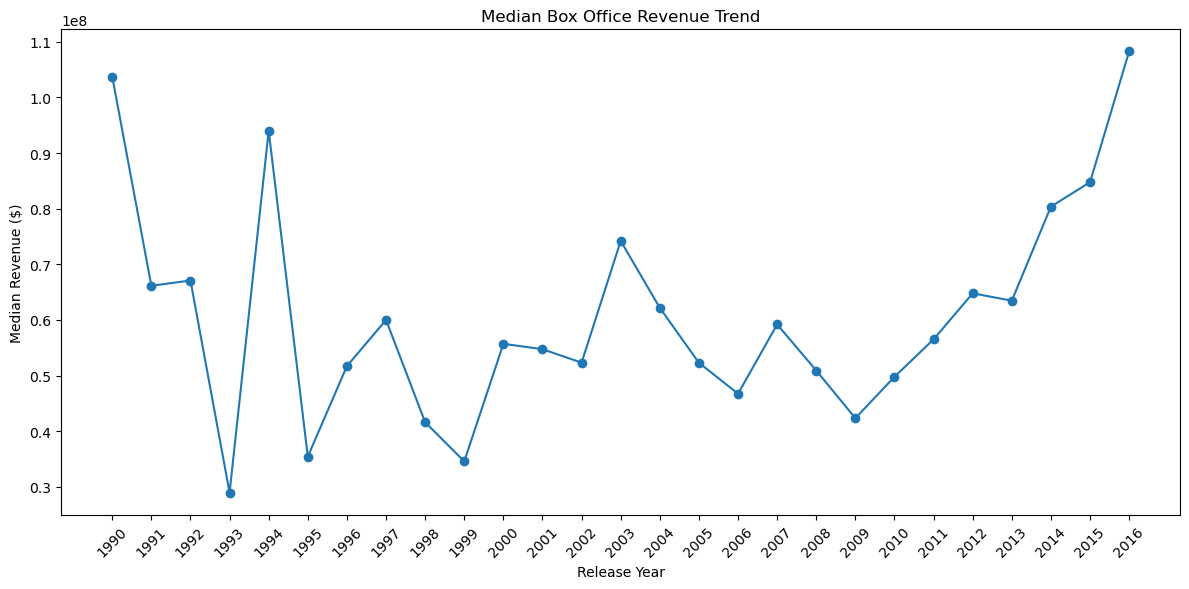

In [88]:
plt.figure(figsize=(12, 6))

plt.plot(
    forecast_data["release_year"],
    forecast_data["median_revenue"],
    marker="o"
)

plt.title("Median Box Office Revenue Trend")
plt.xlabel("Release Year")
plt.ylabel("Median Revenue ($)")
plt.xticks(
    forecast_data["release_year"],
    rotation=45
)

plt.tight_layout()
plt.show()

In [90]:
# ============================================
# FORECASTING - TIME SERIES PREPARATION
# ============================================

ts_data = forecast_data[
    ["release_year", "median_revenue"]
].copy()

ts_data = ts_data.sort_values("release_year")

ts_data = ts_data.set_index("release_year")

ts_data.head()

,median_revenue
release_year,
1990.0,103738726.0
1991.0,66145834.0
1992.0,67094276.0
1993.0,28950000.0
1994.0,94000000.0


In [92]:
ts_data.tail()

,median_revenue
release_year,
2012.0,64793040.0
2013.0,63464861.0
2014.0,80383290.0
2015.0,84769058.0
2016.0,108286421.0


In [94]:
# Use the last 5 years as the test set

train = ts_data.iloc[:-5].copy()
test = ts_data.iloc[-5:].copy()

print("Training period:", train.index.min(), "-", train.index.max())
print("Test period:", test.index.min(), "-", test.index.max())

print("\nTraining observations:", len(train))
print("Test observations:", len(test))

Training period: 1990.0 - 2011.0
Test period: 2012.0 - 2016.0

Training observations: 22
Test observations: 5


In [96]:
# Naive forecasting baseline

naive_predictions = train["median_revenue"].iloc[-1]

naive_forecast = pd.Series(
    naive_predictions,
    index=test.index
)

naive_forecast

release_year
2012.0    56512493.5
2013.0    56512493.5
2014.0    56512493.5
2015.0    56512493.5
2016.0    56512493.5
dtype: float64

In [98]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

naive_mae = mean_absolute_error(
    test["median_revenue"],
    naive_forecast
)

naive_rmse = np.sqrt(
    mean_squared_error(
        test["median_revenue"],
        naive_forecast
    )
)

print("Naive MAE: ${:,.0f}".format(naive_mae))
print("Naive RMSE: ${:,.0f}".format(naive_rmse))

Naive MAE: $23,826,840
Naive RMSE: $28,864,133


In [100]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

model = ExponentialSmoothing(
    train["median_revenue"],
    trend="add",
    damped_trend=True
)

fitted_model = model.fit()

forecast = fitted_model.forecast(steps=5)

forecast

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided and will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/holtwinters/model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


22    5.189307e+07
23    5.188488e+07
24    5.187678e+07
25    5.186876e+07
26    5.186083e+07
dtype: float64

In [102]:
mae = mean_absolute_error(
    test["median_revenue"],
    forecast
)

rmse = np.sqrt(
    mean_squared_error(
        test["median_revenue"],
        forecast
    )
)

print("Exponential Smoothing MAE: ${:,.0f}".format(mae))
print("Exponential Smoothing RMSE: ${:,.0f}".format(rmse))

Exponential Smoothing MAE: $28,462,469
Exponential Smoothing RMSE: $32,800,620


In [104]:
comparison = pd.DataFrame({
    "Actual": test["median_revenue"],
    "Naive Forecast": naive_forecast,
    "Exponential Smoothing": forecast
})

comparison

,Actual,Naive Forecast,Exponential Smoothing
22.0,NaN,NaN,5.189307e+07
23.0,NaN,NaN,5.188488e+07
24.0,NaN,NaN,5.187678e+07
25.0,NaN,NaN,5.186876e+07
26.0,NaN,NaN,5.186083e+07
2012.0,64793040.0,56512493.5,NaN
2013.0,63464861.0,56512493.5,NaN
2014.0,80383290.0,56512493.5,NaN
2015.0,84769058.0,56512493.5,NaN
2016.0,108286421.0,56512493.5,NaN


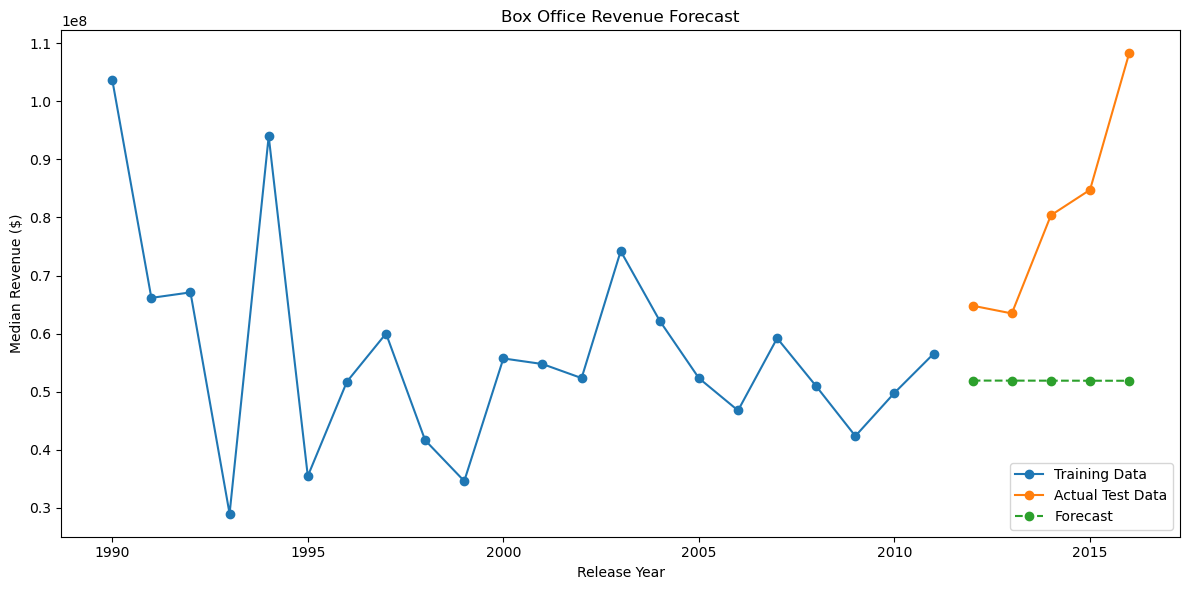

In [106]:
plt.figure(figsize=(12, 6))

plt.plot(
    train.index,
    train["median_revenue"],
    marker="o",
    label="Training Data"
)

plt.plot(
    test.index,
    test["median_revenue"],
    marker="o",
    label="Actual Test Data"
)

plt.plot(
    test.index,
    forecast,
    marker="o",
    linestyle="--",
    label="Forecast"
)

plt.title("Box Office Revenue Forecast")
plt.xlabel("Release Year")
plt.ylabel("Median Revenue ($)")
plt.legend()

plt.tight_layout()
plt.show()

In [108]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Holt's linear trend model
holt_model = ExponentialSmoothing(
    train["median_revenue"],
    trend="add",
    damped_trend=False
)

holt_fit = holt_model.fit()

holt_forecast = holt_fit.forecast(
    steps=len(test)
)

holt_mae = mean_absolute_error(
    test["median_revenue"],
    holt_forecast
)

holt_rmse = np.sqrt(
    mean_squared_error(
        test["median_revenue"],
        holt_forecast
    )
)

print("Holt Linear Trend")
print("MAE: ${:,.0f}".format(holt_mae))
print("RMSE: ${:,.0f}".format(holt_rmse))

Holt Linear Trend
MAE: $28,658,693
RMSE: $33,019,390


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided and will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/holtwinters/model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


In [110]:
# Model comparison

results = pd.DataFrame({
    "Model": [
        "Naive",
        "Damped Exponential Smoothing",
        "Holt Linear Trend"
    ],
    "MAE": [
        naive_mae,
        mae,
        holt_mae
    ],
    "RMSE": [
        naive_rmse,
        rmse,
        holt_rmse
    ]
})

results.sort_values("MAE")

,Model,MAE,RMSE
0,Naive,2.382684e+07,2.886413e+07
1,Damped Exponential Smoothing,2.846247e+07,3.280062e+07
2,Holt Linear Trend,2.865869e+07,3.301939e+07


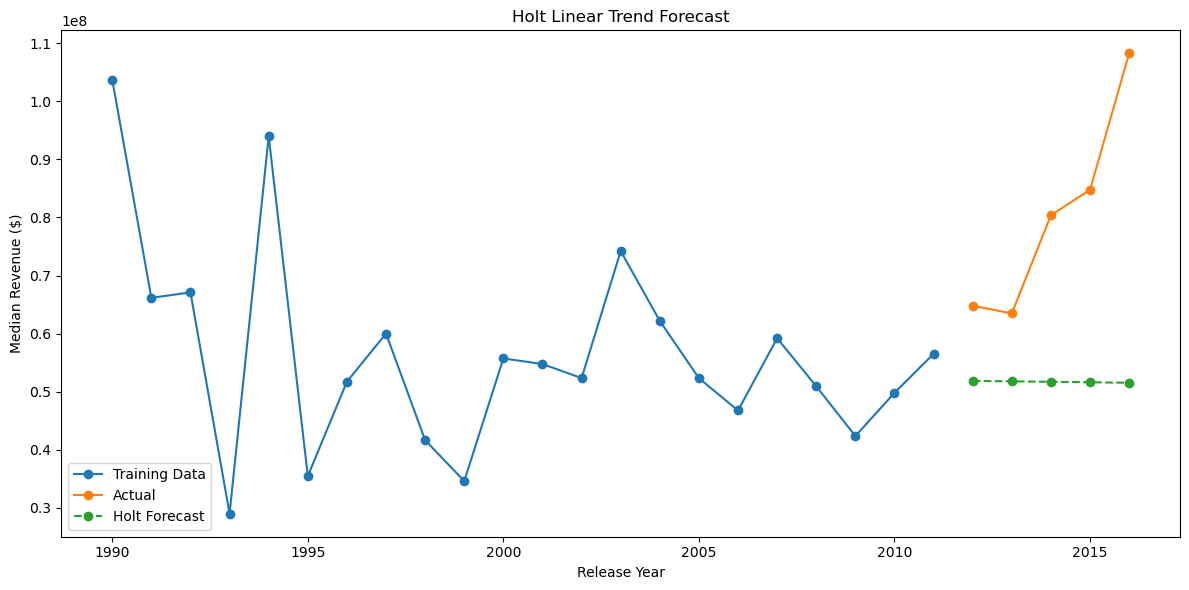

In [112]:
plt.figure(figsize=(12, 6))

plt.plot(
    train.index,
    train["median_revenue"],
    marker="o",
    label="Training Data"
)

plt.plot(
    test.index,
    test["median_revenue"],
    marker="o",
    label="Actual"
)

plt.plot(
    test.index,
    holt_forecast,
    marker="o",
    linestyle="--",
    label="Holt Forecast"
)

plt.title("Holt Linear Trend Forecast")
plt.xlabel("Release Year")
plt.ylabel("Median Revenue ($)")
plt.legend()

plt.tight_layout()
plt.show()

In [118]:
# Load review dataset

reviews = pd.read_csv("tmdb_5000_credits.csv")

reviews.head()

,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,49026,The Dark Knight Rises,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,49529,John Carter,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."


In [121]:
import pandas as pd

reviews = pd.read_csv("IMDB Dataset.csv")

print("Shape:", reviews.shape)
print("\nColumns:")
print(reviews.columns)

print("\nSentiment distribution:")
print(reviews["sentiment"].value_counts())

reviews.head()

Shape: (50000, 2)

Columns:
Index(['review', 'sentiment'], dtype='object')

Sentiment distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [123]:
import re

def clean_text(text):
    text = text.lower()                         # lowercase
    text = re.sub(r'<.*?>', ' ', text)          # remove HTML tags
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)    # remove punctuation/numbers
    text = re.sub(r'\s+', ' ', text).strip()    # remove extra spaces
    return text

reviews["clean_review"] = reviews["review"].apply(clean_text)

reviews[["review", "clean_review", "sentiment"]].head()

,review,clean_review,sentiment
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,a wonderful little production the filming tech...,positive
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,basically there s a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei s love in the time of money is a...,positive


In [125]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

def remove_stopwords(text):
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return " ".join(words)

reviews["processed_review"] = reviews["clean_review"].apply(remove_stopwords)

reviews[["clean_review", "processed_review", "sentiment"]].head()

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/mahithakalinathabotla/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,clean_review,processed_review,sentiment
0,one of the other reviewers has mentioned that ...,one reviewers mentioned watching oz episode ho...,positive
1,a wonderful little production the filming tech...,wonderful little production filming technique ...,positive
2,i thought this was a wonderful way to spend ti...,thought wonderful way spend time hot summer we...,positive
3,basically there s a family where a little boy ...,basically family little boy jake thinks zombie...,negative
4,petter mattei s love in the time of money is a...,petter mattei love time money visually stunnin...,positive


In [127]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    min_df=2,
    max_df=0.95
)

X = tfidf.fit_transform(reviews["processed_review"])
y = reviews["sentiment"]

print("TF-IDF matrix shape:", X.shape)
print("Number of features:", len(tfidf.get_feature_names_out()))

TF-IDF matrix shape: (50000, 5000)
Number of features: 5000


In [129]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("\nTraining sentiment distribution:")
print(y_train.value_counts())
print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training set: (40000, 5000)
Testing set: (10000, 5000)

Training sentiment distribution:
sentiment
positive    20000
negative    20000
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
negative    5000
positive    5000
Name: count, dtype: int64


In [131]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train, y_train)

y_pred = logistic_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Logistic Regression Accuracy: 0.893

Classification Report:
              precision    recall  f1-score   support

    negative       0.90      0.88      0.89      5000
    positive       0.89      0.90      0.89      5000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



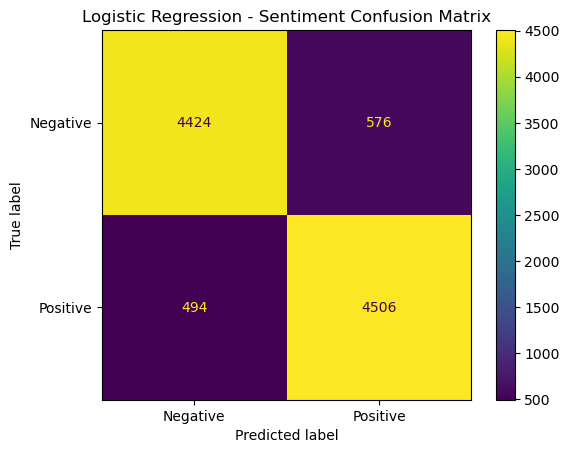

In [133]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot()
plt.title("Logistic Regression - Sentiment Confusion Matrix")
plt.show()

In [135]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

nb_pred = nb_model.predict(X_test)

nb_accuracy = accuracy_score(y_test, nb_pred)

print("Naive Bayes Accuracy:", nb_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, nb_pred))

Naive Bayes Accuracy: 0.8573

Classification Report:
              precision    recall  f1-score   support

    negative       0.86      0.85      0.86      5000
    positive       0.85      0.87      0.86      5000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



In [137]:
model_results = pd.DataFrame({
    "Model": ["Logistic Regression", "Multinomial Naive Bayes"],
    "Accuracy": [accuracy, nb_accuracy],
    "F1 Score": [
        classification_report(y_test, y_pred, output_dict=True)["weighted avg"]["f1-score"],
        classification_report(y_test, nb_pred, output_dict=True)["weighted avg"]["f1-score"]
    ]
})

model_results

,Model,Accuracy,F1 Score
0,Logistic Regression,0.8930,0.892993
1,Multinomial Naive Bayes,0.8573,0.857290


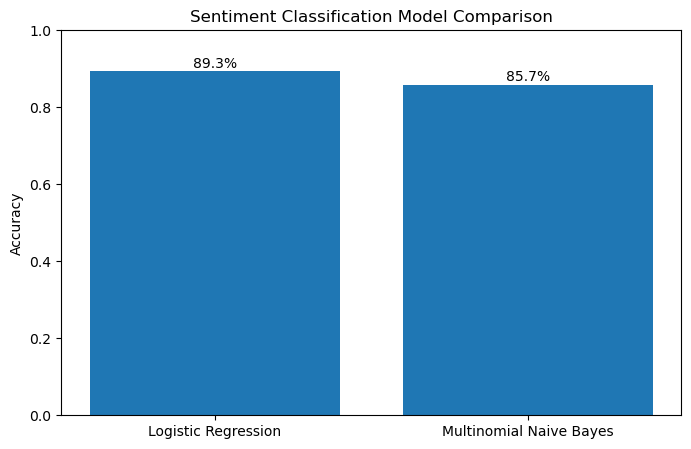

In [139]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(model_results["Model"], model_results["Accuracy"])

plt.title("Sentiment Classification Model Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

for i, value in enumerate(model_results["Accuracy"]):
    plt.text(i, value + 0.01, f"{value:.1%}", ha="center")

plt.show()

In [141]:
import numpy as np

feature_names = np.array(tfidf.get_feature_names_out())

# Get Logistic Regression coefficients
coefficients = logistic_model.coef_[0]

# Most positive words
positive_words = feature_names[np.argsort(coefficients)[-20:]][::-1]

# Most negative words
negative_words = feature_names[np.argsort(coefficients)[:20]]

print("Top 20 Positive Words:")
print(positive_words)

print("\nTop 20 Negative Words:")
print(negative_words)

Top 20 Positive Words:
['great' 'excellent' 'perfect' 'best' 'amazing' 'wonderful' 'loved'
 'hilarious' 'enjoyed' 'brilliant' 'favorite' 'enjoyable' 'fun' 'today'
 'definitely' 'superb' 'well' 'highly' 'fantastic' 'gem']

Top 20 Negative Words:
['worst' 'waste' 'awful' 'bad' 'boring' 'poor' 'terrible' 'nothing'
 'poorly' 'dull' 'horrible' 'worse' 'disappointing' 'disappointment'
 'fails' 'unfortunately' 'stupid' 'minutes' 'annoying' 'instead']


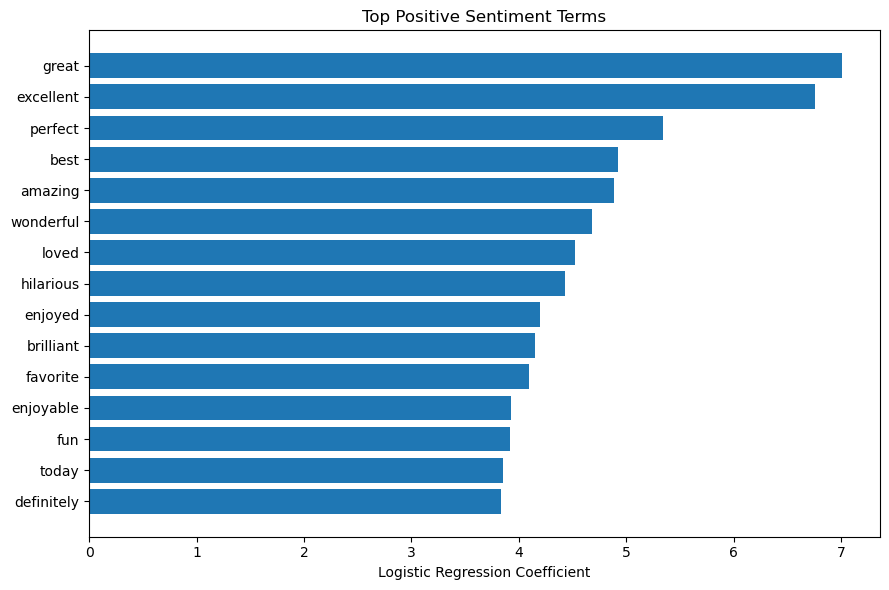

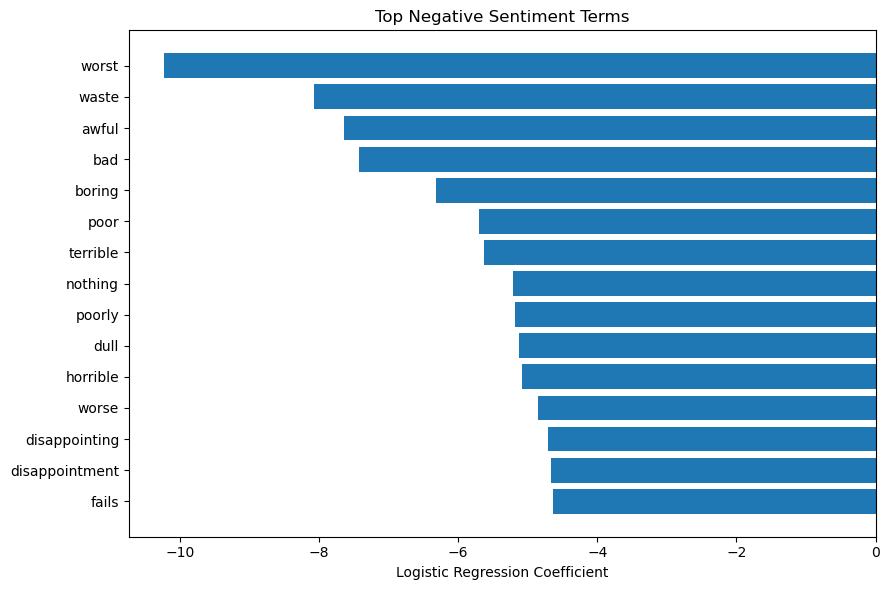

In [143]:
import matplotlib.pyplot as plt

# Get coefficient values for the top words
positive_indices = np.argsort(coefficients)[-15:][::-1]
negative_indices = np.argsort(coefficients)[:15]

positive_terms = feature_names[positive_indices]
positive_scores = coefficients[positive_indices]

negative_terms = feature_names[negative_indices]
negative_scores = coefficients[negative_indices]

# Positive words
plt.figure(figsize=(9, 6))
plt.barh(positive_terms[::-1], positive_scores[::-1])
plt.title("Top Positive Sentiment Terms")
plt.xlabel("Logistic Regression Coefficient")
plt.tight_layout()
plt.show()

# Negative words
plt.figure(figsize=(9, 6))
plt.barh(negative_terms[::-1], negative_scores[::-1])
plt.title("Top Negative Sentiment Terms")
plt.xlabel("Logistic Regression Coefficient")
plt.tight_layout()
plt.show()

In [145]:
sentiment_counts = reviews["sentiment"].value_counts()

print("Sentiment Counts:")
print(sentiment_counts)

print("\nSentiment Percentages:")
print((sentiment_counts / len(reviews) * 100).round(2))

Sentiment Counts:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Sentiment Percentages:
sentiment
positive    50.0
negative    50.0
Name: count, dtype: float64


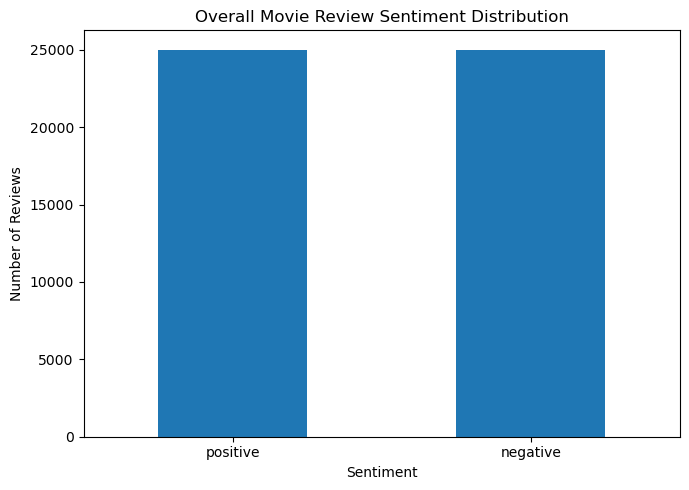

In [147]:
plt.figure(figsize=(7, 5))

sentiment_counts.plot(
    kind="bar",
    title="Overall Movie Review Sentiment Distribution"
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [149]:
rating_revenue = movies.dropna(
    subset=["vote_average", "revenue"]
).copy()

rating_revenue = rating_revenue[
    rating_revenue["vote_count"] >= 100
]

print("Movies analyzed:", len(rating_revenue))

print(
    rating_revenue[["vote_average", "revenue"]].corr()
)

Movies analyzed: 2803
              vote_average   revenue
vote_average      1.000000  0.163153
revenue           0.163153  1.000000


In [153]:
#Rating vs. Box Office Revenue
rating_revenue = movies.dropna(
    subset=["vote_average", "revenue"]
).copy()

# Keep movies with enough votes for a more reliable rating
rating_revenue = rating_revenue[
    rating_revenue["vote_count"] >= 100
]

print("Movies analyzed:", len(rating_revenue))

print("\nCorrelation between rating and revenue:")
print(
    rating_revenue[["vote_average", "revenue"]].corr()
)

Movies analyzed: 2803

Correlation between rating and revenue:
              vote_average   revenue
vote_average      1.000000  0.163153
revenue           0.163153  1.000000


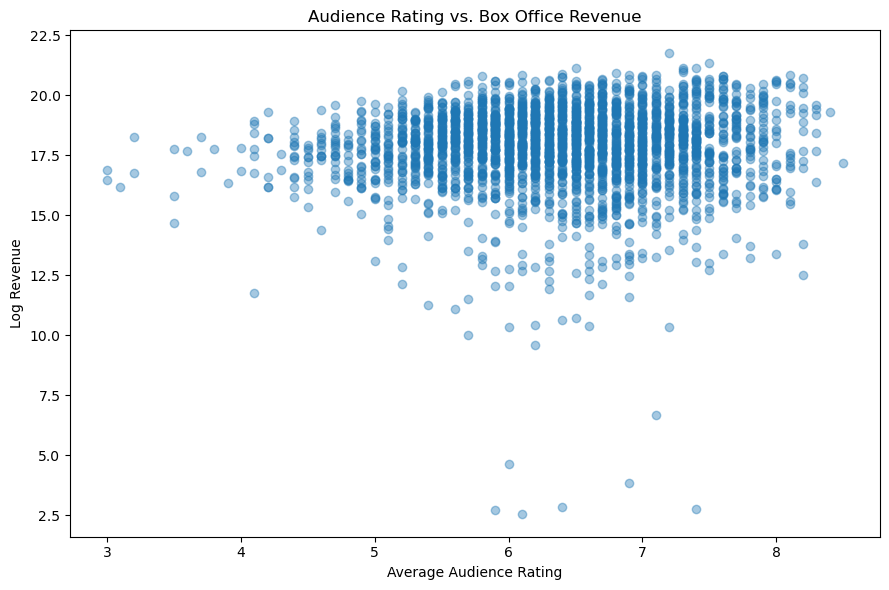

In [155]:
#Visualize Rating vs. Revenue
import numpy as np
import matplotlib.pyplot as plt

rating_revenue["log_revenue"] = np.log1p(
    rating_revenue["revenue"]
)

plt.figure(figsize=(9, 6))

plt.scatter(
    rating_revenue["vote_average"],
    rating_revenue["log_revenue"],
    alpha=0.4
)

plt.xlabel("Average Audience Rating")
plt.ylabel("Log Revenue")
plt.title("Audience Rating vs. Box Office Revenue")

plt.tight_layout()
plt.show()

In [157]:
#Popularity vs. Revenue
popularity_revenue = movies.dropna(
    subset=["popularity", "revenue"]
).copy()

print("Movies analyzed:", len(popularity_revenue))

print("\nCorrelation between popularity and revenue:")
print(
    popularity_revenue[["popularity", "revenue"]].corr()
)

Movies analyzed: 3376

Correlation between popularity and revenue:
            popularity   revenue
popularity    1.000000  0.605994
revenue       0.605994  1.000000


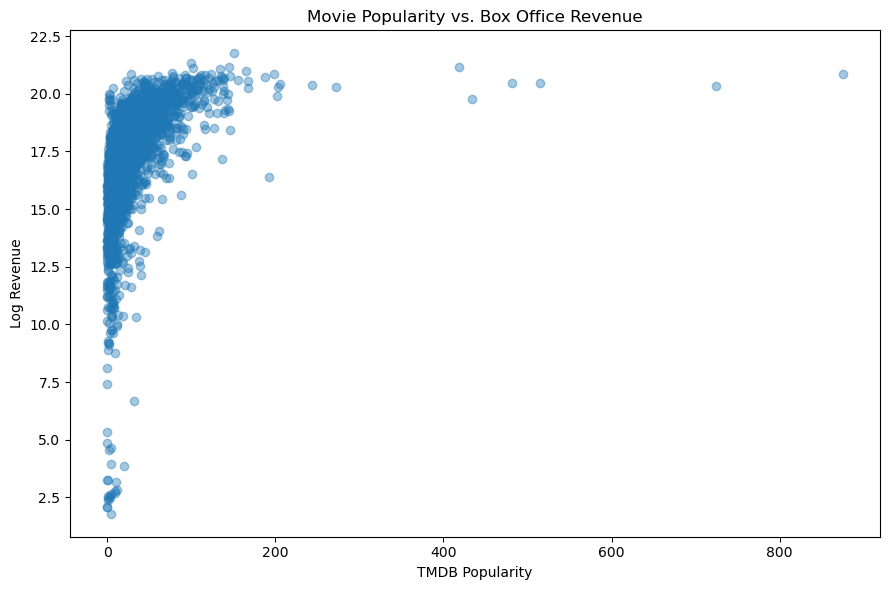

In [159]:
popularity_revenue["log_revenue"] = np.log1p(
    popularity_revenue["revenue"]
)

plt.figure(figsize=(9, 6))

plt.scatter(
    popularity_revenue["popularity"],
    popularity_revenue["log_revenue"],
    alpha=0.4
)

plt.xlabel("TMDB Popularity")
plt.ylabel("Log Revenue")
plt.title("Movie Popularity vs. Box Office Revenue")

plt.tight_layout()
plt.show()

In [161]:
#Correlation
popularity_revenue = movies.dropna(
    subset=["popularity", "revenue"]
).copy()

print("Movies analyzed:", len(popularity_revenue))

correlation = popularity_revenue[
    ["popularity", "revenue"]
].corr()

print("\nCorrelation between popularity and revenue:")
print(correlation)

Movies analyzed: 3376

Correlation between popularity and revenue:
            popularity   revenue
popularity    1.000000  0.605994
revenue       0.605994  1.000000


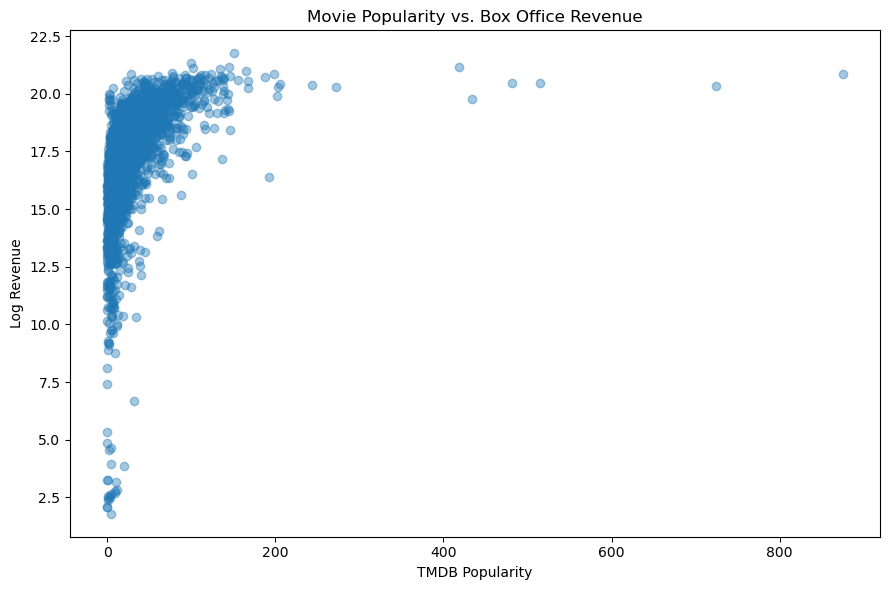

In [163]:
#Visualization
popularity_revenue["log_revenue"] = np.log1p(
    popularity_revenue["revenue"]
)

plt.figure(figsize=(9, 6))

plt.scatter(
    popularity_revenue["popularity"],
    popularity_revenue["log_revenue"],
    alpha=0.4
)

plt.xlabel("TMDB Popularity")
plt.ylabel("Log Revenue")
plt.title("Movie Popularity vs. Box Office Revenue")

plt.tight_layout()
plt.show()

In [165]:
#Budget vs. Revenue
budget_revenue = movies.dropna(
    subset=["budget", "revenue"]
).copy()

print("Movies analyzed:", len(budget_revenue))

print("\nCorrelation between budget and revenue:")
print(
    budget_revenue[["budget", "revenue"]].corr()
)

Movies analyzed: 3229

Correlation between budget and revenue:
           budget   revenue
budget   1.000000  0.705399
revenue  0.705399  1.000000


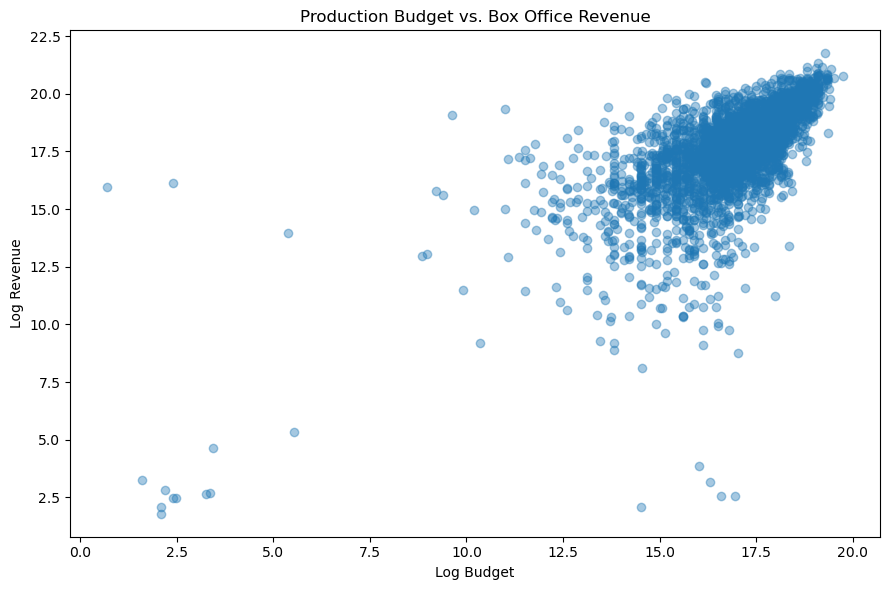

In [167]:
budget_revenue["log_budget"] = np.log1p(
    budget_revenue["budget"]
)

budget_revenue["log_revenue"] = np.log1p(
    budget_revenue["revenue"]
)

plt.figure(figsize=(9, 6))

plt.scatter(
    budget_revenue["log_budget"],
    budget_revenue["log_revenue"],
    alpha=0.4
)

plt.xlabel("Log Budget")
plt.ylabel("Log Revenue")
plt.title("Production Budget vs. Box Office Revenue")

plt.tight_layout()
plt.show()

In [171]:
# Use the full historical dataset to create the final forecast

final_series = ts_data["median_revenue"]

last_value = final_series.iloc[-1]
last_year = int(final_series.index.max())

forecast_years = range(last_year + 1, last_year + 6)

final_forecast = pd.Series(
    last_value,
    index=forecast_years
)

print("Last historical year:", last_year)
print("Last observed median revenue:", last_value)

print("\n5-Year Forecast:")
print(final_forecast)

Last historical year: 2016
Last observed median revenue: 108286421.0

5-Year Forecast:
2017    108286421.0
2018    108286421.0
2019    108286421.0
2020    108286421.0
2021    108286421.0
dtype: float64


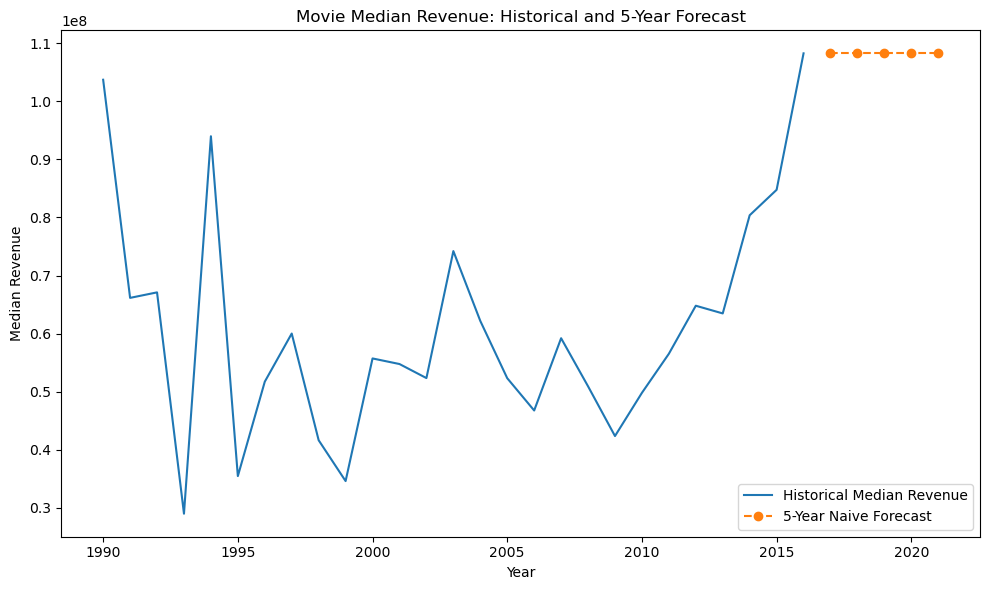

In [173]:
plt.figure(figsize=(10, 6))

plt.plot(
    final_series.index,
    final_series.values,
    label="Historical Median Revenue"
)

plt.plot(
    final_forecast.index,
    final_forecast.values,
    marker="o",
    linestyle="--",
    label="5-Year Naive Forecast"
)

plt.xlabel("Year")
plt.ylabel("Median Revenue")
plt.title("Movie Median Revenue: Historical and 5-Year Forecast")
plt.legend()

plt.tight_layout()
plt.show()

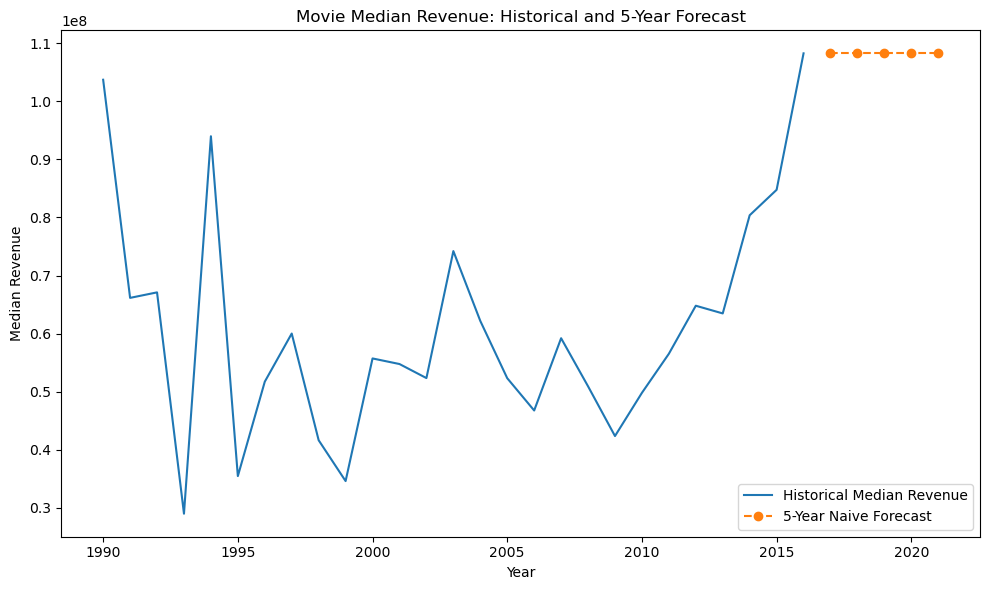

In [175]:
#Plot the final forecast
plt.figure(figsize=(10, 6))

plt.plot(
    final_series.index,
    final_series.values,
    label="Historical Median Revenue"
)

plt.plot(
    final_forecast.index,
    final_forecast.values,
    marker="o",
    linestyle="--",
    label="5-Year Naive Forecast"
)

plt.xlabel("Year")
plt.ylabel("Median Revenue")
plt.title("Movie Median Revenue: Historical and 5-Year Forecast")
plt.legend()

plt.tight_layout()
plt.show()

In [177]:
forecast_table = final_forecast.reset_index()

forecast_table.columns = [
    "forecast_year",
    "forecast_median_revenue"
]

forecast_table

,forecast_year,forecast_median_revenue
0,2017,108286421.0
1,2018,108286421.0
2,2019,108286421.0
3,2020,108286421.0
4,2021,108286421.0


In [179]:
dashboard_data = movies[
    [
        "id",
        "title",
        "release_date",
        "release_year",
        "budget",
        "revenue",
        "popularity",
        "vote_average",
        "vote_count",
        "runtime"
    ]
].copy()

dashboard_data["log_revenue"] = np.log1p(
    dashboard_data["revenue"]
)

dashboard_data["profit"] = (
    dashboard_data["revenue"] - dashboard_data["budget"]
)

dashboard_data.head()

,id,title,release_date,release_year,budget,revenue,popularity,vote_average,vote_count,runtime,log_revenue,profit
0,19995,Avatar,2009-12-10,2009.0,237000000.0,2.787965e+09,150.437577,7.2,11800,162.0,21.748578,2.550965e+09
1,285,Pirates of the Caribbean: At World's End,2007-05-19,2007.0,300000000.0,9.610000e+08,139.082615,6.9,4500,169.0,20.683485,6.610000e+08
2,206647,Spectre,2015-10-26,2015.0,245000000.0,8.806746e+08,107.376788,6.3,4466,148.0,20.596199,6.356746e+08
3,49026,The Dark Knight Rises,2012-07-16,2012.0,250000000.0,1.084939e+09,112.312950,7.6,9106,165.0,20.804790,8.349391e+08
4,49529,John Carter,2012-03-07,2012.0,260000000.0,2.841391e+08,43.926995,6.1,2124,132.0,19.464974,2.413910e+07


In [181]:
print("Dashboard dataset shape:", dashboard_data.shape)
print("\nMissing values:")
print(dashboard_data.isnull().sum())

Dashboard dataset shape: (4803, 12)

Missing values:
id                 0
title              0
release_date       1
release_year       1
budget          1037
revenue         1427
popularity         0
vote_average       0
vote_count         0
runtime            2
log_revenue     1427
profit          1574
dtype: int64


In [183]:
dashboard_data = movies[
    [
        "id",
        "title",
        "release_date",
        "release_year",
        "budget",
        "revenue",
        "popularity",
        "vote_average",
        "vote_count",
        "runtime"
    ]
].copy()

dashboard_data["log_revenue"] = np.log1p(
    dashboard_data["revenue"]
)

dashboard_data["profit"] = (
    dashboard_data["revenue"] - dashboard_data["budget"]
)

print("Dashboard dataset shape:", dashboard_data.shape)

dashboard_data.head()

Dashboard dataset shape: (4803, 12)


,id,title,release_date,release_year,budget,revenue,popularity,vote_average,vote_count,runtime,log_revenue,profit
0,19995,Avatar,2009-12-10,2009.0,237000000.0,2.787965e+09,150.437577,7.2,11800,162.0,21.748578,2.550965e+09
1,285,Pirates of the Caribbean: At World's End,2007-05-19,2007.0,300000000.0,9.610000e+08,139.082615,6.9,4500,169.0,20.683485,6.610000e+08
2,206647,Spectre,2015-10-26,2015.0,245000000.0,8.806746e+08,107.376788,6.3,4466,148.0,20.596199,6.356746e+08
3,49026,The Dark Knight Rises,2012-07-16,2012.0,250000000.0,1.084939e+09,112.312950,7.6,9106,165.0,20.804790,8.349391e+08
4,49529,John Carter,2012-03-07,2012.0,260000000.0,2.841391e+08,43.926995,6.1,2124,132.0,19.464974,2.413910e+07


In [185]:
print("Missing values:")
print(dashboard_data.isnull().sum())

Missing values:
id                 0
title              0
release_date       1
release_year       1
budget          1037
revenue         1427
popularity         0
vote_average       0
vote_count         0
runtime            2
log_revenue     1427
profit          1574
dtype: int64


In [187]:
dashboard_data.to_csv(
    "movie_dashboard_data.csv",
    index=False
)

forecast_table.to_csv(
    "movie_revenue_forecast.csv",
    index=False
)

print("Files exported successfully!")

Files exported successfully!


In [10]:
print("reviews exists:", "reviews" in globals())
print("tfidf exists:", "tfidf" in globals())
print("logistic_model exists:", "logistic_model" in globals())
print("positive_terms exists:", "positive_terms" in globals())

reviews exists: False
tfidf exists: False
logistic_model exists: False
positive_terms exists: False
